# WARNING: Running the same code on different machine architectures can produce different clustering results. The following code was developed and executed on a Windows machine, so its results differ from those obtained on macOS systems. For consistency, the results showed in the report are the ones to be considered valid.

# Optics

In [1]:
import profile
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sys
import os
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from scipy.spatial.distance import pdist, squareform
from pyclustering.cluster import cluster_visualizer
from pyclustering.cluster.optics import optics, ordering_analyser, ordering_visualizer
from pyclustering.samples.definitions import FCPS_SAMPLES
from pyclustering.utils import read_sample
from sklearn.metrics import silhouette_score, davies_bouldin_score


sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du
from src.utils import utils as ut
profile_df = pd.read_csv("../../data/profiles/patient_profile.csv")

profile_df.drop_duplicates(inplace=True)


profile_df

,subject_id,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,...,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),min_ph,max_pco2,abnormal_lab_event_ratio
0,10000980,1,0,1,0,0,0,0,0,0,...,0.0,5.286957,2.0,-0.475000,0.251724,0.328571,1.000000,0.0,0.0,0.408284
1,10002013,1,0,0,0,0,0,0,0,0,...,0.0,4.634783,0.5,0.025000,0.389655,0.714286,0.000000,0.0,0.0,0.375000
2,10002155,1,0,0,0,0,0,0,0,0,...,0.0,5.661538,10.5,0.125000,0.341379,0.500000,0.000000,0.8,1.3,0.386760
3,10004457,0,0,0,1,0,0,0,0,0,...,0.0,0.000000,0.0,-0.075000,0.396552,0.357143,1.228571,0.0,0.0,0.333333
4,10007058,1,0,0,0,0,0,0,0,0,...,0.0,4.582609,1.5,-0.315789,0.220000,1.416667,0.742857,0.0,0.0,0.375000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4379,19998596,0,0,0,0,0,0,0,0,1,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4380,19998597,0,0,0,0,0,1,0,0,0,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4381,19998598,0,0,0,0,0,0,0,0,1,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4382,19998599,0,0,0,0,0,1,0,0,0,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000


In [2]:
# Correlation
profile_df['subject_id'] = profile_df['subject_id'].astype(str)
# Select only numeric columns from the patient profile
numeric_cols = profile_df.select_dtypes(include='number').columns
profile_num= profile_df[numeric_cols]

# Print features with correlation higher than 0.7
corr_matrix = profile_num.corr().abs()
high_corr_var=np.where(corr_matrix>0.7)
high_corr_var=[(corr_matrix.columns[x],corr_matrix.columns[y]) for x,y in zip(*high_corr_var) if x!=y and x<y]
high_corr_var


[('unique_microorganisms_count', 'unique_antibiotics_count')]

In [3]:
# Drop highly correlated features
profile_df = profile_df.drop(columns=['unique_antibiotics_count'])

# Identify categorical columns to exclude
categorical_cols = ['subject_id', 'gender'
                    , 'ACS_acute_ischemic', 'Chronic_ischemic', 
                   'Heart_failure', 'Valvular_nonrheumatic', 'Myocarditis_or_cardiomyopathy', 
                   'Pericardial_disease', 'Endocarditis', 'Cardiac_arrest', 
                   'Arrhythmias_or_conduction'
                   ]

# Select only numeric columns for clustering
numeric_cols = [col for col in profile_df.columns if col not in categorical_cols]
numeric_df = profile_df[numeric_cols]

# Verify selected numeric columns
print("Numeric columns for clustering:")
print(numeric_cols)
print(f"\nNumber of features: {len(numeric_cols)}")


Numeric columns for clustering:
['number_of_hadm', 'age', 'lab_event_count', 'microbio_test_count', 'unique_microorganisms_count', 'unique_procedures_count', 'max_glucose', 'max_potassium', 'max_sodium', 'max_creatinine', 'max_bicarbonate', 'max_calcium, total', 'max_urea nitrogen', 'max_troponin t', 'max_ntprobnp', 'max_ptt', 'max_inr(pt)', 'max_hemoglobin', 'max_platelet count', 'max_white blood cells', 'max_cholesterol ratio (total/hdl)', 'min_ph', 'max_pco2', 'abnormal_lab_event_ratio']

Number of features: 24


In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(numeric_df)






OPTICS with radius=7, neighbors=5
Clusters found: 1
Noise points: 801
  Cluster 0: 3583 patients


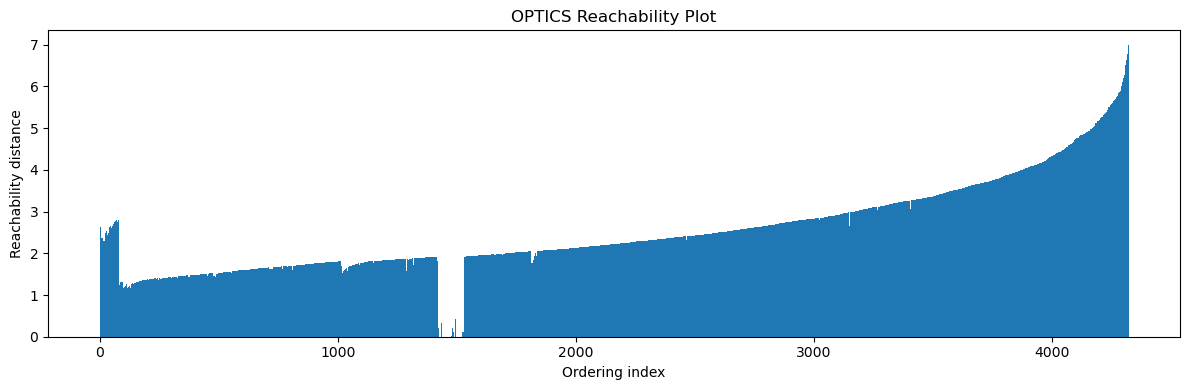


OPTICS with radius=7, neighbors=25
Clusters found: 1
Noise points: 229
  Cluster 0: 4155 patients


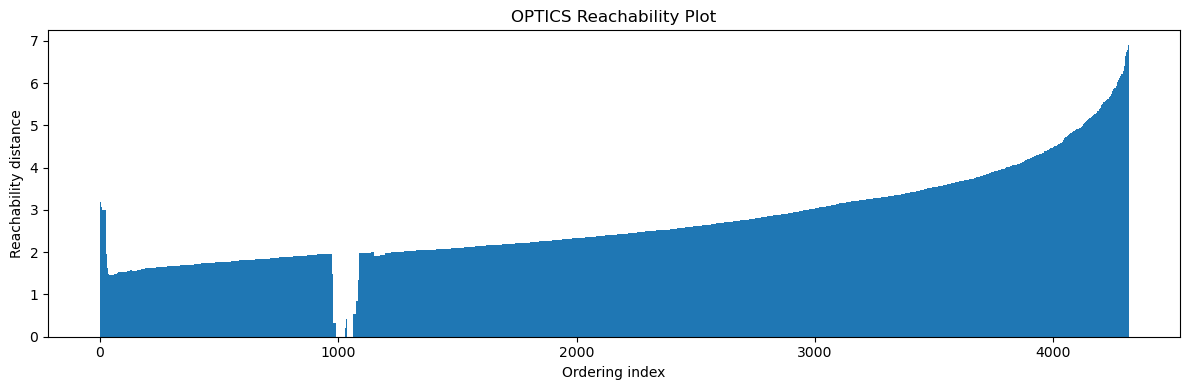


OPTICS with radius=7, neighbors=50
Clusters found: 1
Noise points: 235
  Cluster 0: 4149 patients


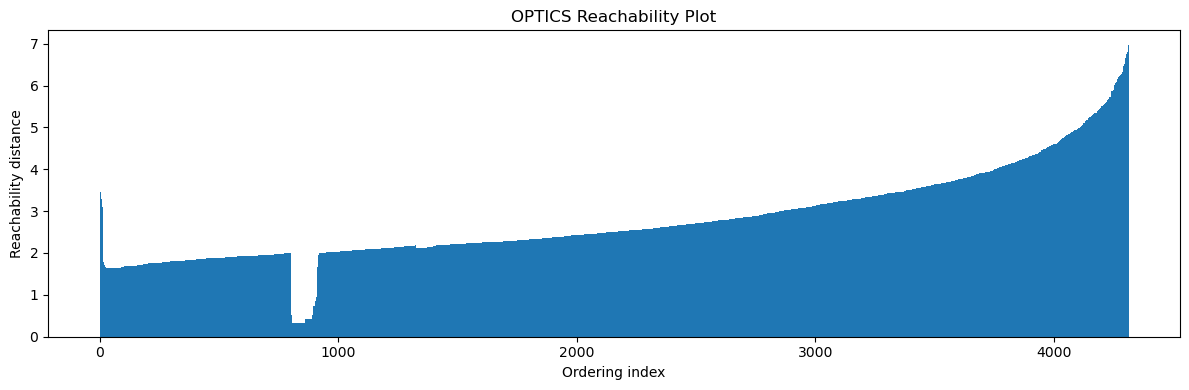

In [5]:
from pyclustering.cluster.optics import optics, ordering_analyser, ordering_visualizer
from pyclustering.cluster import cluster_visualizer

# Use standardized data (converted to list)
sample = X.tolist() 


radius = 7
neighbors_list = [5, 25, 50]
amount_of_clusters = 2 

# Loop over neighbor values
for neighbors in neighbors_list:
    print(f"\n{'='*60}")
    print(f"OPTICS with radius={radius}, neighbors={neighbors}")
    print(f"{'='*60}")
                                    
    # Initialization and processing
    optics_instance = optics(sample, radius, neighbors, amount_of_clusters)
    optics_instance.process()
    
    # Results
    clusters = optics_instance.get_clusters()
    noise = optics_instance.get_noise()
    ordering = optics_instance.get_ordering()
    
   
    
    print(f"Clusters found: {len(clusters)}")
    print(f"Noise points: {len(noise)}")
    for i, cluster in enumerate(clusters):
        print(f"  Cluster {i}: {len(cluster)} patients")
    

 # Reachability distances aligned to ordering
    analyser = ordering_analyser(ordering)
    reachability = ordering

    plt.figure(figsize=(12, 4))
    plt.bar(range(len(reachability)), reachability, width=1.0)
    plt.xlabel("Ordering index")
    plt.ylabel("Reachability distance")
    plt.title("OPTICS Reachability Plot")
    plt.tight_layout()
    plt.show()


The reachability plots obtained using OPTICS for different values of the minimum number of neighbors show a highly consistent global structure. Across all parameter settings, the plots are characterized by a largely continuous reachability profile, without the presence of multiple deep and well-separated valleys that would indicate distinct and stable clusters at a single density scale.

Following the exploratory analysis of the reachability plots, a value of min_samples = 25 was selected to focus on stable density structures and reduce the influence of local fluctuations. At this scale, two consistent low-reachability regions were observed. By lowering the reachability threshold, these regions were isolated as compact high-density subgroups. This step was performed as an additional analysis aimed at characterizing particularly homogeneous patient subsets, rather than enforcing a global clustering of the entire dataset.

Clusters found: 2
Noise points: 3721
  Cluster 0: 551 patients
  Cluster 1: 112 patients


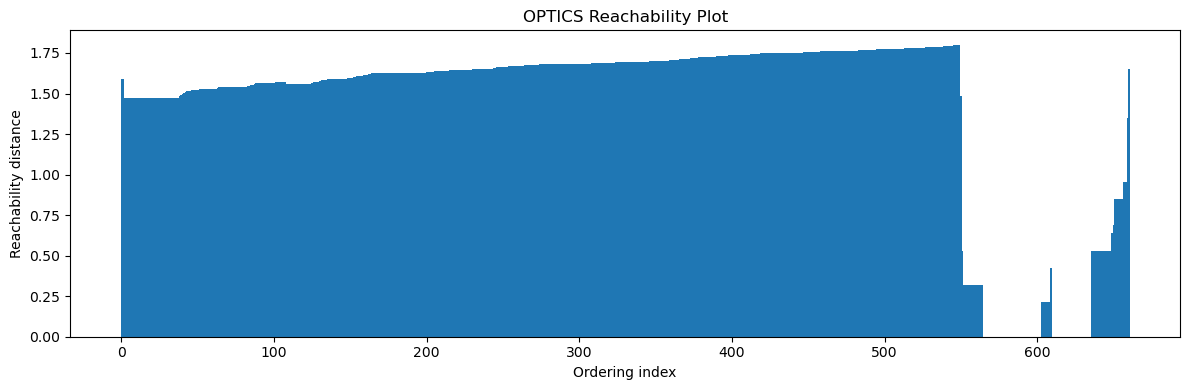

In [6]:
import numpy as np
import matplotlib.pyplot as plt
# Initialization and processing
optics_instance = optics(sample, 1.8, 25, amount_of_clusters)
optics_instance.process()
    
# Results
clusters = optics_instance.get_clusters()
noise = optics_instance.get_noise()
ordering = optics_instance.get_ordering()
    
print(f"Clusters found: {len(clusters)}")
print(f"Noise points: {len(noise)}")
for i, cluster in enumerate(clusters):
    print(f"  Cluster {i}: {len(cluster)} patients")

# Reachability distances aligned to ordering
analyser = ordering_analyser(ordering)
reachability = ordering

plt.figure(figsize=(12, 4))
plt.bar(range(len(reachability)), reachability, width=1.0)
plt.xlabel("Ordering index")
plt.ylabel("Reachability distance")
plt.title("OPTICS Reachability Plot")
plt.tight_layout()
plt.show()


In [7]:
#cluster label of optics
labels = np.full(len(X), -1)  # Initialize all as noise (-1)
for cluster_id, cluster in enumerate(clusters):
    for index in cluster:
        labels[index] = cluster_id
# Count patients per cluster
unique_values, value_counts = np.unique(labels, return_counts=True)

for c, n in zip(unique_values, value_counts):
    print(f"Cluster {int(c)}: {int(n)} patients")   



Cluster -1: 3721 patients
Cluster 0: 551 patients
Cluster 1: 112 patients


In [8]:
profile_df = profile_df.copy()
profile_df["cluster"] = labels
# Create DataFrame with standardized features
X_df = pd.DataFrame(
    X,
    columns=numeric_df.columns,
    index=profile_df.index
)

X_df["cluster"] = profile_df["cluster"]

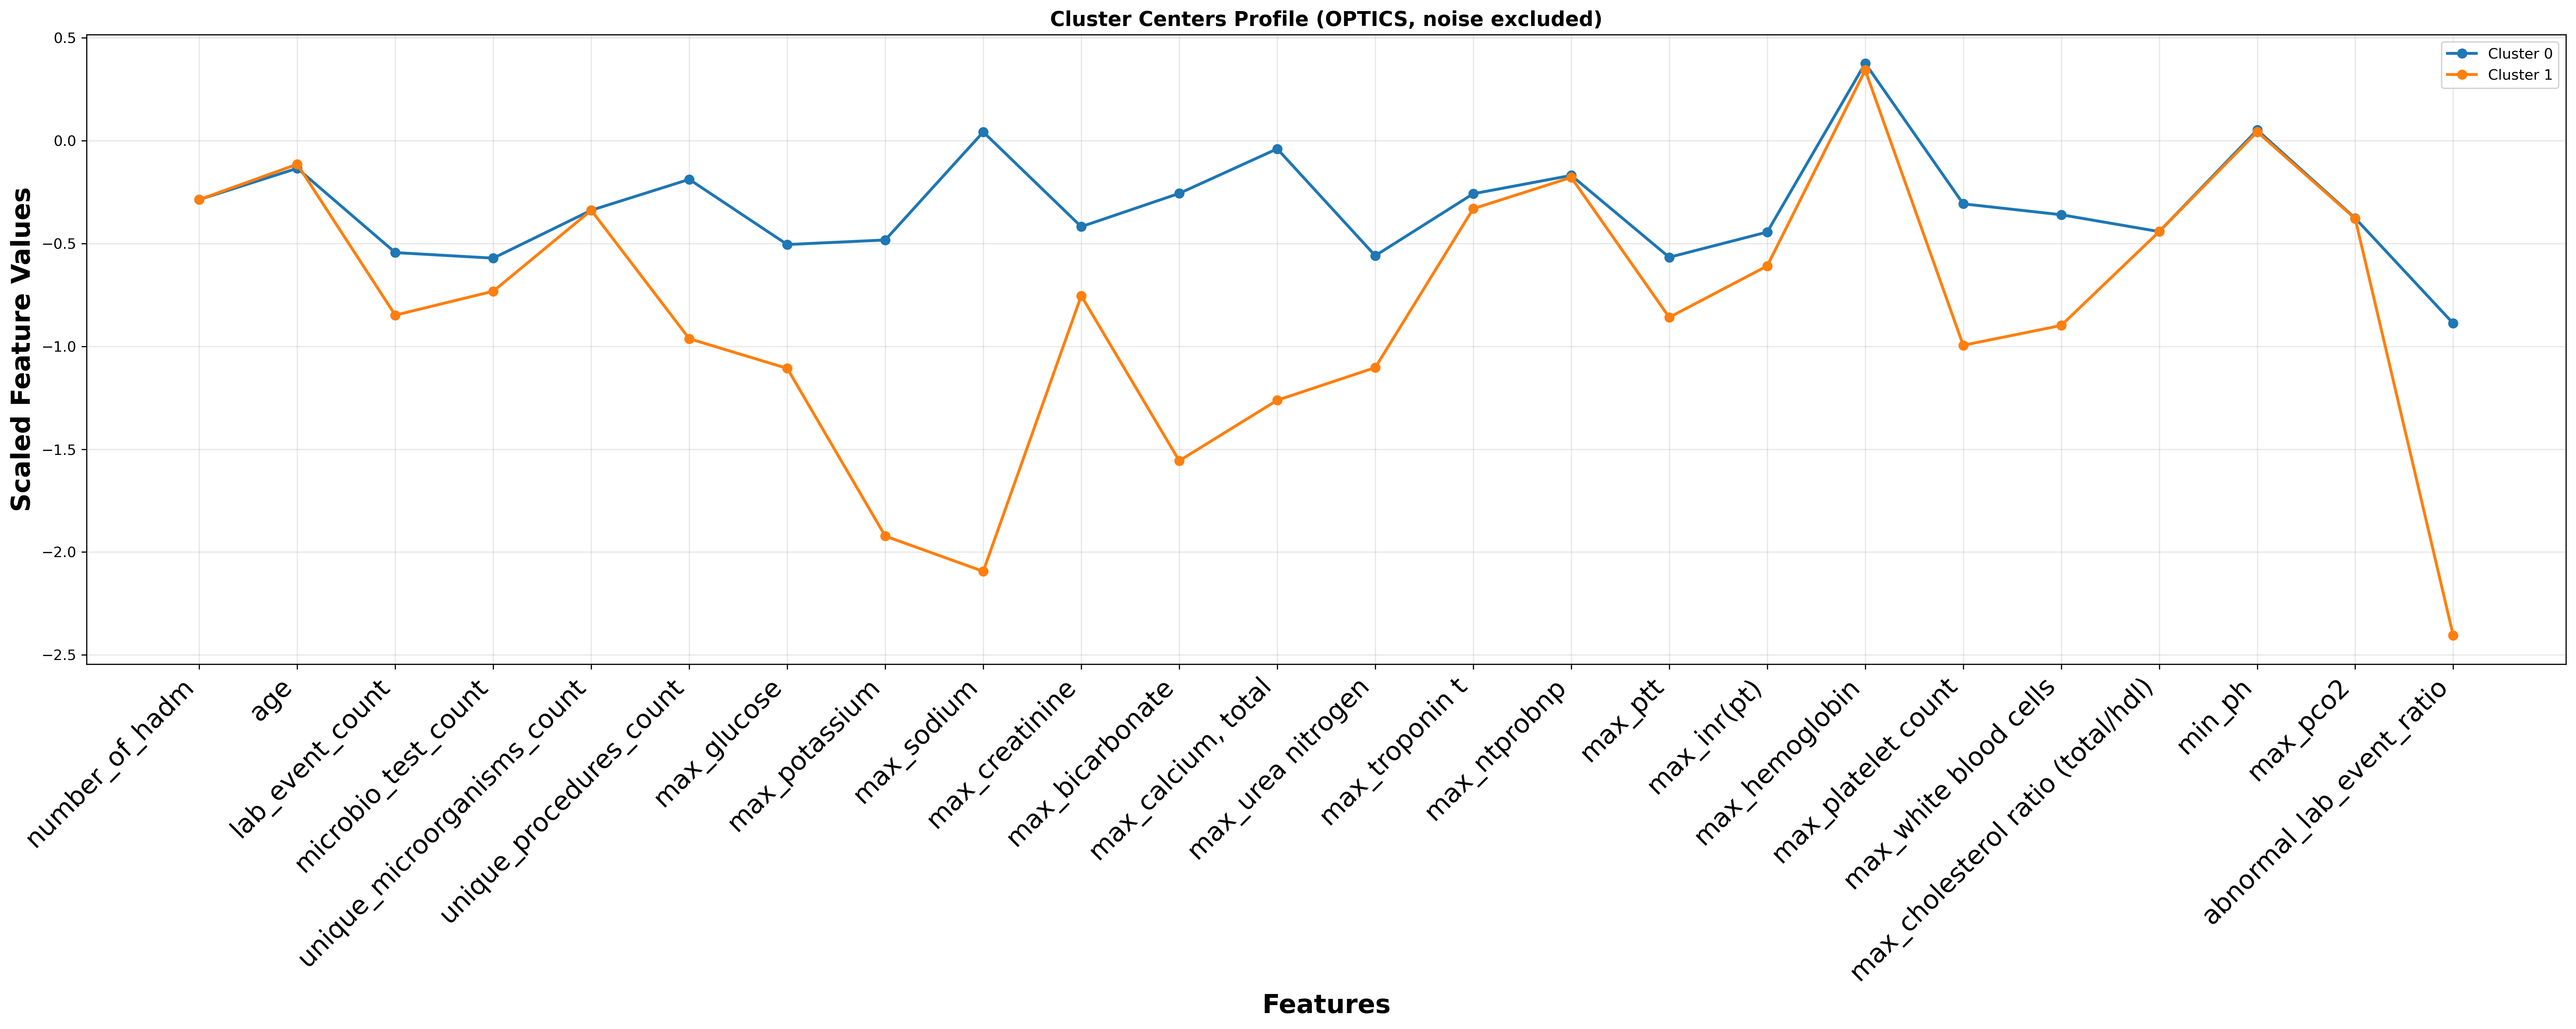

In [9]:
# Plot cluster centers profile using OPTICS labels (noise excluded)
import numpy as np
import matplotlib.pyplot as plt
# Compute centers for non-noise clusters
unique_clusters = sorted(c for c in X_df["cluster"].unique() if c != -1)

centers = np.vstack([
    X_df.loc[X_df["cluster"] == k, numeric_df.columns].mean(axis=0)
    for k in unique_clusters
])


plt.figure(figsize=(25, 10), dpi=300)

for i, center in enumerate(centers):
    plt.plot(
        center,
        marker='o',
        linewidth=2,
        markersize=6,
        label=f'Cluster {unique_clusters[i]}'
    )

plt.xticks(
    range(len(numeric_df.columns)),
    numeric_df.columns,
    fontsize=18,
    rotation=45,
    ha='right'
)
plt.xlabel('Features', fontsize=18, fontweight='bold')
plt.ylabel('Scaled Feature Values', fontsize=18, fontweight='bold')
plt.title('Cluster Centers Profile (OPTICS, noise excluded)', fontsize=14, fontweight='bold')
plt.legend(fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



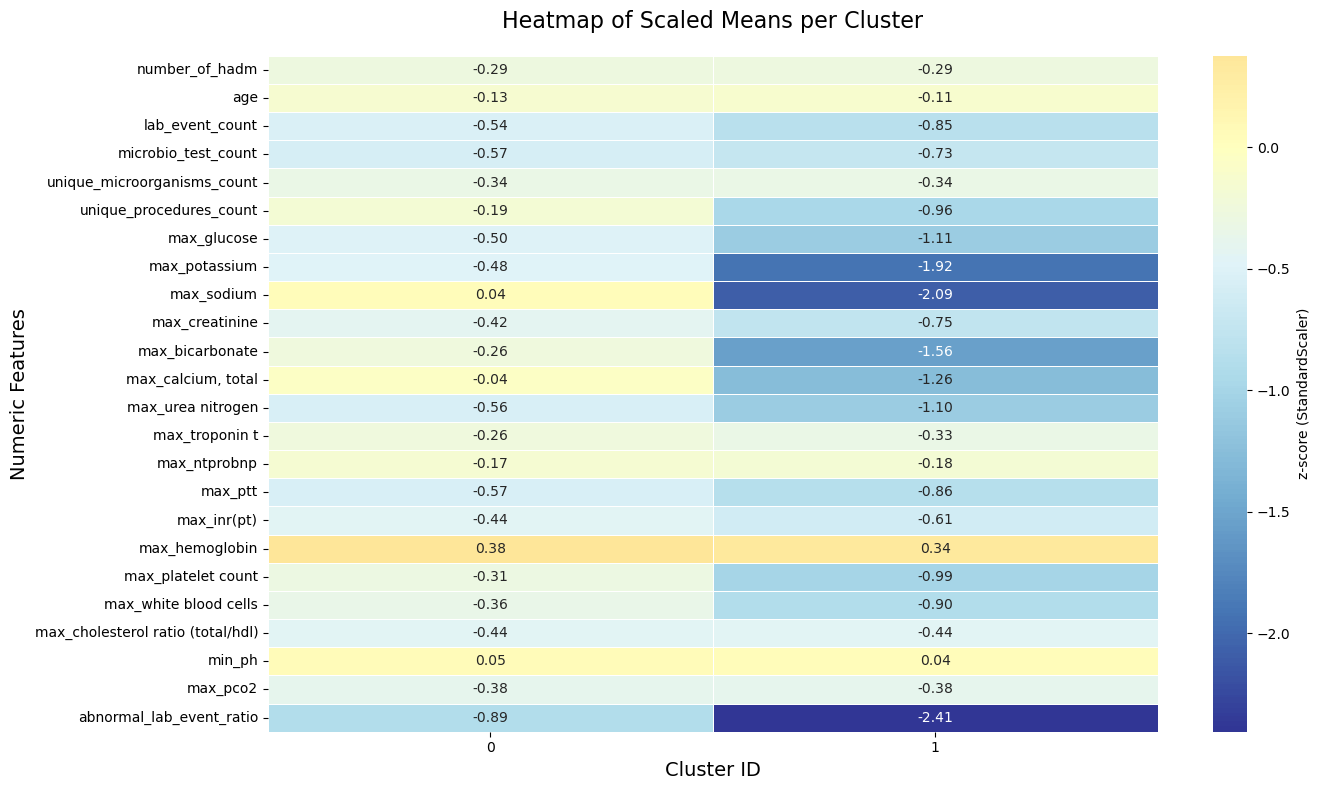

In [10]:
valid_mask = profile_df["cluster"] != -1
cluster_means_scaled = X_df[valid_mask].groupby("cluster").mean()
plt.figure(figsize=(14, 8))


sns.heatmap(
    cluster_means_scaled.T,
    annot=True,
    fmt=".2f",
    cmap="RdYlBu_r",
    center=0,                         
    linewidths=0.5,
    cbar_kws={"label": "z-score (StandardScaler)"}
)

plt.title("Heatmap of Scaled Means per Cluster", fontsize=16, pad=20)
plt.xlabel("Cluster ID", fontsize=14)
plt.ylabel("Numeric Features", fontsize=14)
plt.tight_layout()
plt.show()

C:\Users\Cominotti\AppData\Local\Temp\ipykernel_22876\2880147096.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=profile_df[valid_mask], x='cluster', y=feature, ax=axes[idx], palette='Set2')
C:\Users\Cominotti\AppData\Local\Temp\ipykernel_22876\2880147096.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=profile_df[valid_mask], x='cluster', y=feature, ax=axes[idx], palette='Set2')
C:\Users\Cominotti\AppData\Local\Temp\ipykernel_22876\2880147096.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=profile_df[valid_mask]

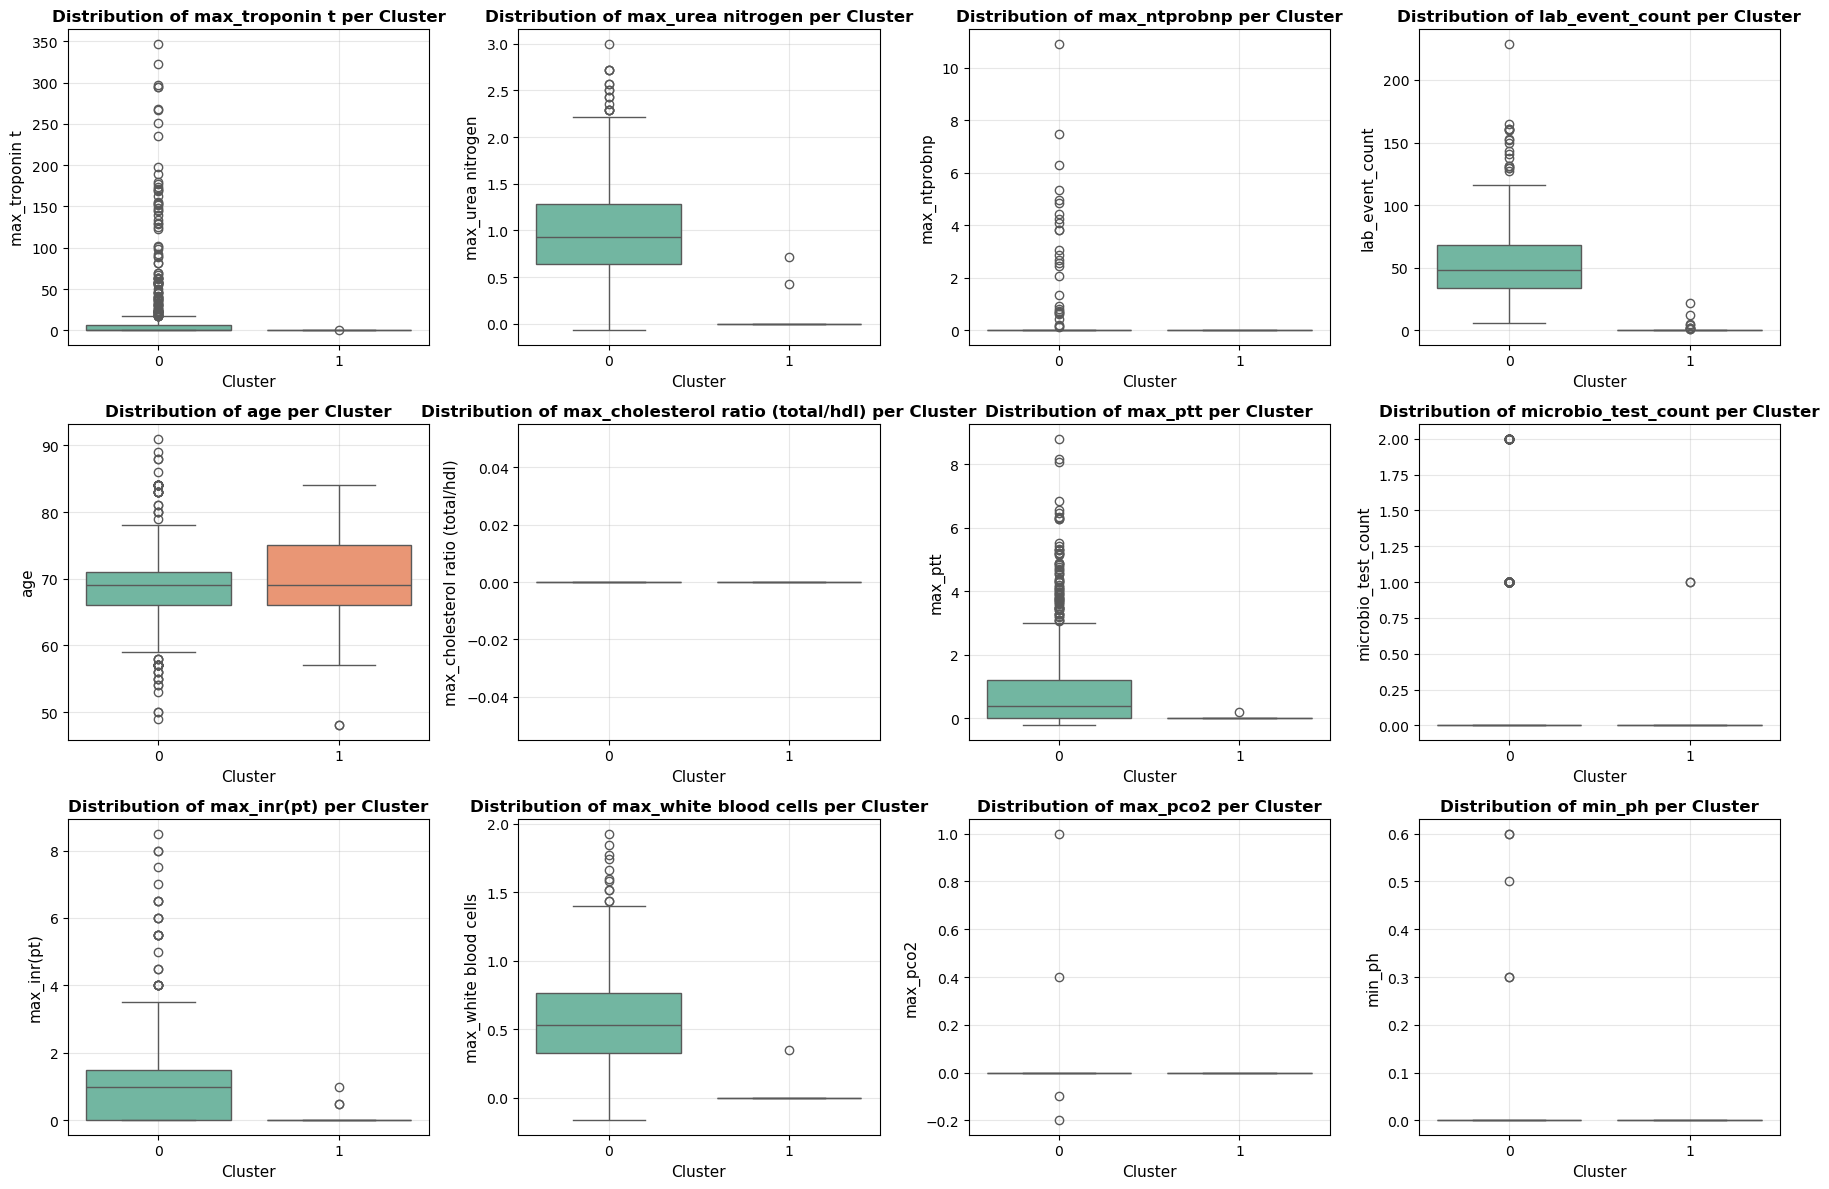

In [11]:
# Select key features to visualize
key_features = ['max_troponin t','max_urea nitrogen','max_ntprobnp', 'lab_event_count', 'age','max_cholesterol ratio (total/hdl)',
                'max_ptt','microbio_test_count','max_inr(pt)','max_white blood cells','max_pco2','min_ph']

# Filter only non-noise points (cluster != -1) for the plot
valid_mask = profile_df["cluster"] != -1

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for idx, feature in enumerate(key_features):
    sns.boxplot(data=profile_df[valid_mask], x='cluster', y=feature, ax=axes[idx], palette='Set2')
    axes[idx].set_title(f'Distribution of {feature} per Cluster', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Cluster', fontsize=11)
    axes[idx].set_ylabel(feature, fontsize=11)
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

The OPTICS analysis identified two high-density subgroups with moderately different multivariate profiles. Cluster 0 is characterized by relatively higher values across several laboratory and monitoring-related variables, indicating greater clinical complexity and variability. Cluster 1 shows consistently lower values and a more homogeneous profile, suggesting a comparatively more stable patient subgroup.

As the features were standardized using z-scores, negative centroid values indicate that cluster-specific means lie below the global dataset average and should be interpreted in relative terms.*

The DBSCAN analysis resulted in a single dominant cluster associated with low silhouette scores, suggesting the absence of well-separated global clusters and indicating a largely continuous data structure.

The OPTICS analysis complements this finding by providing a detailed view of the dataset’s density landscape. The reachability plots reveal a continuous density profile with localized high-density regions embedded within a heterogeneous background population.

These observations clarify why DBSCAN fails to identify multiple stable clusters using a single density threshold, while OPTICS enables the identification of compact subgroups without enforcing a global partition. Together, the two methods consistently indicate that patient stratification in this dataset is better described in terms of local density variations rather than distinct global clusters.